In [ ]:
!pip -q install river scikit-learn pandas numpy matplotlib

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from river import tree, forest

warnings.filterwarnings("ignore")
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
uploaded = files.upload()

filename = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(filename)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Saving creditcard.csv to creditcard (2).csv
Dataset loaded successfully.
Dataset shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
assert "Class" in df.columns, "Dataset must contain the Class column."
assert "Time" in df.columns, "Dataset must contain the Time column."

df = df.dropna().sort_values("Time").reset_index(drop=True)

# Features and target
feature_cols = [
    col for col in df.columns
    if col not in ["Class", "Time"]
]

X = df[feature_cols].astype("float32")
y = df["Class"].astype("int8")

print("Total transactions:", len(df))
print("Number of features:", len(feature_cols))
print("Legitimate transactions:", int((y == 0).sum()))
print("Fraudulent transactions:", int((y == 1).sum()))
print("Fraud percentage:", round(100 * y.mean(), 4), "%")

display(df["Class"].value_counts().rename("Count").to_frame())

Total transactions: 284807
Number of features: 29
Legitimate transactions: 284315
Fraudulent transactions: 492
Fraud percentage: 0.1727 %


,Count
Class,
0,284315
1,492


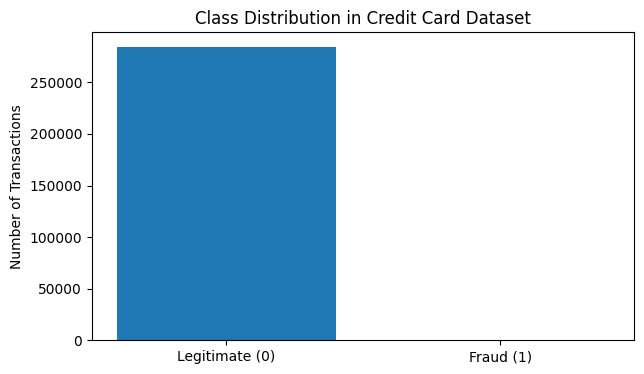

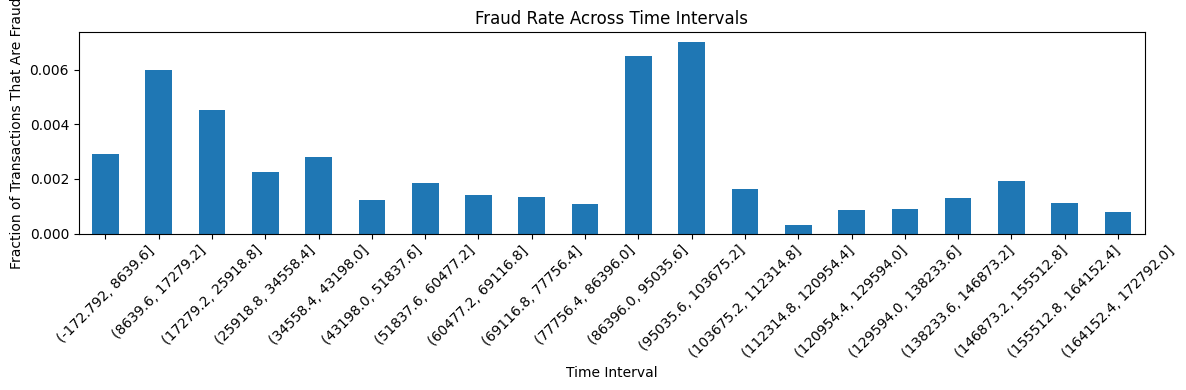

In [ ]:
counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(
    ["Legitimate (0)", "Fraud (1)"],
    [counts.get(0, 0), counts.get(1, 0)]
)
plt.title("Class Distribution in Credit Card Dataset")
plt.ylabel("Number of Transactions")
plt.show()

plt.figure(figsize=(12, 4))
df.groupby(
    pd.cut(df["Time"], bins=20, duplicates="drop"),
    observed=False
)["Class"].mean().plot(kind="bar")

plt.title("Fraud Rate Across Time Intervals")
plt.ylabel("Fraction of Transactions That Are Fraud")
plt.xlabel("Time Interval")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
INITIAL_TRAIN_SIZE = int(0.20 * len(df))

X_train = X.iloc[:INITIAL_TRAIN_SIZE]
y_train = y.iloc[:INITIAL_TRAIN_SIZE]

X_stream = X.iloc[INITIAL_TRAIN_SIZE:]
y_stream = y.iloc[INITIAL_TRAIN_SIZE:]

print("Initial training transactions:", len(X_train))
print("Incoming evaluation transactions:", len(X_stream))
print("Training fraud cases:", int(y_train.sum()))
print("Evaluation fraud cases:", int(y_stream.sum()))

Initial training transactions: 56961
Incoming evaluation transactions: 227846
Training fraud cases: 157
Evaluation fraud cases: 335


In [ ]:
# 1. Traditional batch-learning baseline
batch_tree = DecisionTreeClassifier(
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

# 2. Standard Hoeffding Tree
hoeffding_tree = tree.HoeffdingTreeClassifier(
    grace_period=200,
    delta=1e-5,
    leaf_prediction="nba"
)

# 3. Adaptive Hoeffding Tree
adaptive_tree = tree.HoeffdingAdaptiveTreeClassifier(
    grace_period=200,
    delta=1e-5,
    leaf_prediction="nba"
)

# 4. Adaptive Random Forest ensemble
adaptive_forest = forest.ARFClassifier(
    n_models=5,
    seed=42
)

online_models = {
    "Hoeffding Tree": hoeffding_tree,
    "Adaptive Hoeffding Tree": adaptive_tree,
    "Adaptive Random Forest": adaptive_forest
}

print("All four models are ready.")

All four models are ready.


In [ ]:
start_time = time.time()

# Batch training
batch_tree.fit(X_train, y_train)

# Online warm-up
train_records = X_train.to_numpy(dtype=np.float32)
train_labels = y_train.to_numpy(dtype=np.int8)
feature_names = list(feature_cols)

for i in range(len(train_labels)):
    x = dict(zip(feature_names, train_records[i]))
    label = int(train_labels[i])

    for model in online_models.values():
        model.learn_one(x, label)

    if (i + 1) % 10000 == 0:
        print(f"Warm-up: {i + 1:,} transactions processed")

print(f"Initial training completed in {time.time() - start_time:.1f} seconds.")

Warm-up: 10,000 transactions processed
Warm-up: 20,000 transactions processed
Warm-up: 30,000 transactions processed
Warm-up: 40,000 transactions processed
Warm-up: 50,000 transactions processed
Initial training completed in 62.2 seconds.


In [ ]:
X_eval = X_stream.to_numpy(dtype=np.float32)
y_eval = y_stream.to_numpy(dtype=np.int8)

# Traditional tree makes predictions but does not update
batch_predictions = batch_tree.predict(X_stream)
batch_probabilities = batch_tree.predict_proba(X_stream)[:, 1]

# Storage for online model predictions
online_predictions = {name: [] for name in online_models}
online_scores = {name: [] for name in online_models}

start_time = time.time()

for i in range(len(y_eval)):

    x = dict(zip(feature_names, X_eval[i]))
    true_label = int(y_eval[i])

    # Predict first; learn only afterward
    for name, model in online_models.items():

        prediction = model.predict_one(x)
        probabilities = model.predict_proba_one(x) or {}

        # Default prediction when a model has not produced one yet
        if prediction is None:
            prediction = 0

        fraud_score = float(probabilities.get(1, 0.0))

        online_predictions[name].append(int(prediction))
        online_scores[name].append(fraud_score)

        # Reveal the label and update the model
        model.learn_one(x, true_label)

    if (i + 1) % 10000 == 0:
        elapsed = time.time() - start_time
        print(
            f"Processed {i + 1:,}/{len(y_eval):,} incoming transactions "
            f"({elapsed:.1f} seconds elapsed)"
        )

print("Incoming-stream experiment completed.")

Processed 10,000/227,846 incoming transactions (11.9 seconds elapsed)
Processed 20,000/227,846 incoming transactions (24.5 seconds elapsed)
Processed 30,000/227,846 incoming transactions (37.1 seconds elapsed)
Processed 40,000/227,846 incoming transactions (49.7 seconds elapsed)
Processed 50,000/227,846 incoming transactions (62.4 seconds elapsed)
Processed 60,000/227,846 incoming transactions (75.3 seconds elapsed)
Processed 70,000/227,846 incoming transactions (88.0 seconds elapsed)
Processed 80,000/227,846 incoming transactions (100.8 seconds elapsed)
Processed 90,000/227,846 incoming transactions (114.0 seconds elapsed)
Processed 100,000/227,846 incoming transactions (127.6 seconds elapsed)
Processed 110,000/227,846 incoming transactions (141.0 seconds elapsed)
Processed 120,000/227,846 incoming transactions (154.5 seconds elapsed)
Processed 130,000/227,846 incoming transactions (168.0 seconds elapsed)
Processed 140,000/227,846 incoming transactions (181.7 seconds elapsed)
Processe

In [ ]:
all_predictions = {
    "Traditional Decision Tree": np.asarray(batch_predictions, dtype=int)
}

all_scores = {
    "Traditional Decision Tree": np.asarray(batch_probabilities, dtype=float)
}

for name in online_models:
    all_predictions[name] = np.asarray(online_predictions[name], dtype=int)
    all_scores[name] = np.asarray(online_scores[name], dtype=float)


def evaluate_model(y_true, predictions, scores):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_true, scores
        )
    }


metrics = []

for name in all_predictions:
    row = evaluate_model(
        y_eval,
        all_predictions[name],
        all_scores[name]
    )
    row["Model"] = name
    metrics.append(row)

metrics_df = pd.DataFrame(metrics).set_index("Model")

print("Model performance on the incoming transaction stream:")
display(metrics_df.sort_values("Average Precision", ascending=False).round(4))

Model performance on the incoming transaction stream:


,Accuracy,Precision,Recall,F1 Score,Average Precision
Model,,,,,
Adaptive Random Forest,0.9988,1.0000,0.1701,0.2908,0.5907
Traditional Decision Tree,0.9964,0.2516,0.7164,0.3724,0.5662
Hoeffding Tree,0.9985,0.0000,0.0000,0.0000,0.0015
Adaptive Hoeffding Tree,0.9985,0.0000,0.0000,0.0000,0.0015


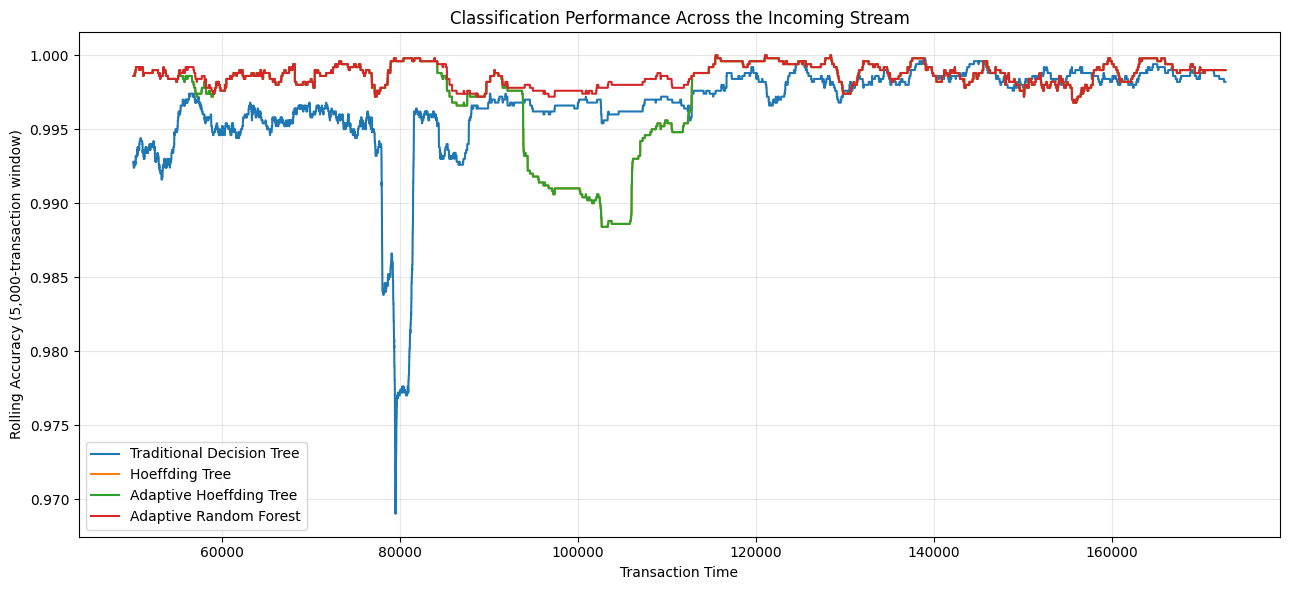

In [ ]:
WINDOW = 5000
rolling_accuracy = {}

for name, predictions in all_predictions.items():

    correct = (predictions == y_eval).astype(float)

    rolling_accuracy[name] = (
        pd.Series(correct)
        .rolling(WINDOW, min_periods=WINDOW)
        .mean()
    )

plt.figure(figsize=(13, 6))

# Retrieve the Time values corresponding to the stream indices from the original df
time_values = df.loc[X_stream.index, "Time"].to_numpy()

for name, values in rolling_accuracy.items():
    plt.plot(
        time_values,
        values.to_numpy(),
        label=name,
        linewidth=1.5
    )

plt.xlabel("Transaction Time")
plt.ylabel(f"Rolling Accuracy ({WINDOW:,}-transaction window)")
plt.title("Classification Performance Across the Incoming Stream")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

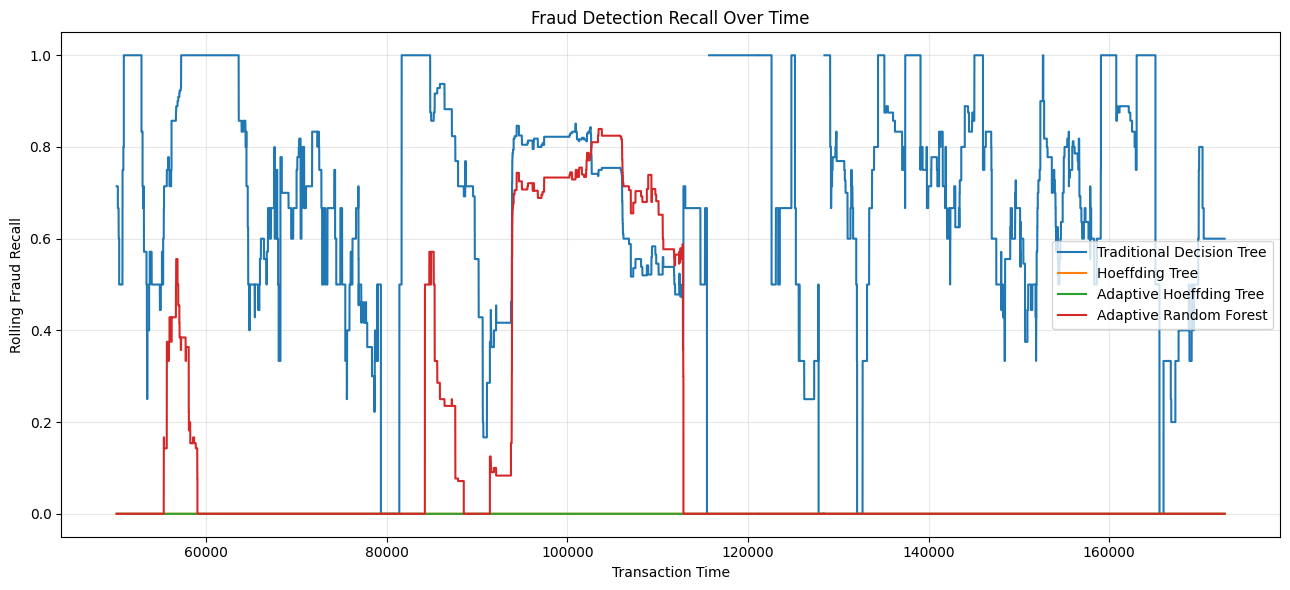

In [ ]:
rolling_recall = {}

for name, predictions in all_predictions.items():

    true_positive = ((predictions == 1) & (y_eval == 1)).astype(int)
    actual_positive = (y_eval == 1).astype(int)

    tp_sum = pd.Series(true_positive).rolling(
        WINDOW, min_periods=WINDOW
    ).sum()

    positive_sum = pd.Series(actual_positive).rolling(
        WINDOW, min_periods=WINDOW
    ).sum()

    recall_values = (tp_sum / positive_sum.replace(0, np.nan))
    rolling_recall[name] = recall_values

plt.figure(figsize=(13, 6))

# Retrieve the correct Time values corresponding to the stream indices from the original df
time_values = df.loc[X_stream.index, "Time"].to_numpy()

for name, values in rolling_recall.items():
    plt.plot(
        time_values,
        values.to_numpy(),
        label=name
    )

plt.xlabel("Transaction Time")
plt.ylabel("Rolling Fraud Recall")
plt.title("Fraud Detection Recall Over Time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

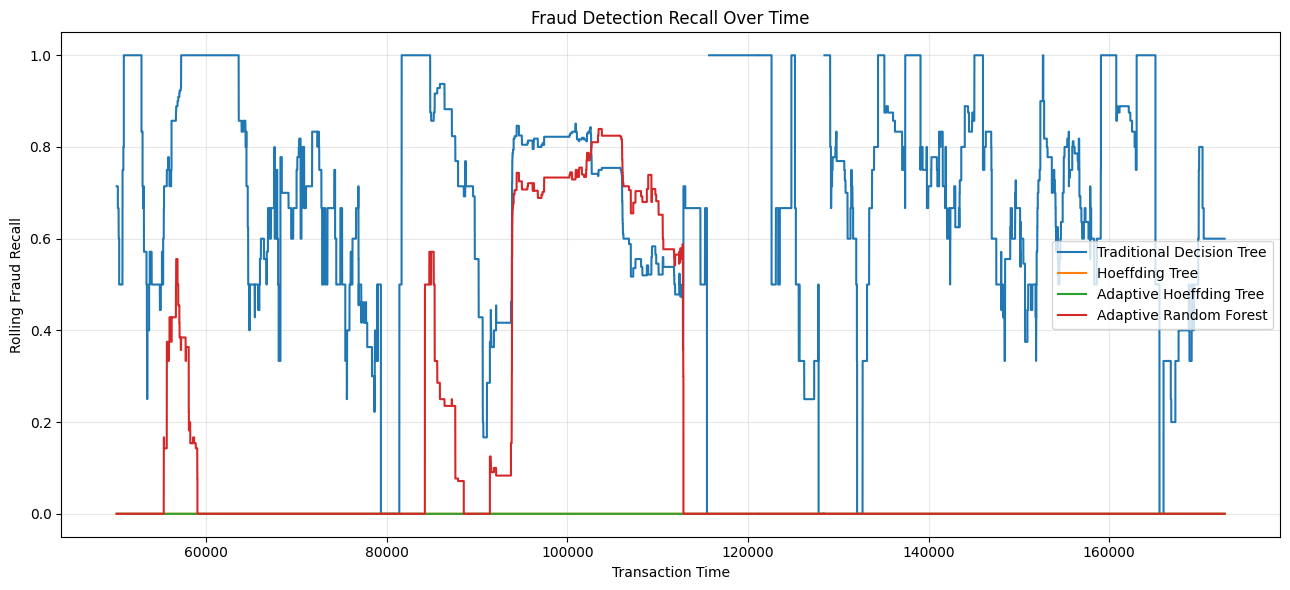

In [ ]:
rolling_recall = {}

for name, predictions in all_predictions.items():

    true_positive = ((predictions == 1) & (y_eval == 1)).astype(int)
    actual_positive = (y_eval == 1).astype(int)

    tp_sum = pd.Series(true_positive).rolling(
        WINDOW, min_periods=WINDOW
    ).sum()

    positive_sum = pd.Series(actual_positive).rolling(
        WINDOW, min_periods=WINDOW
    ).sum()

    recall_values = (tp_sum / positive_sum.replace(0, np.nan))
    rolling_recall[name] = recall_values

plt.figure(figsize=(13, 6))

# Retrieve the correct Time values corresponding to the stream indices from the original df
time_values = df.loc[X_stream.index, "Time"].to_numpy()

for name, values in rolling_recall.items():
    plt.plot(
        time_values,
        values.to_numpy(),
        label=name
    )

plt.xlabel("Transaction Time")
plt.ylabel("Rolling Fraud Recall")
plt.title("Fraud Detection Recall Over Time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

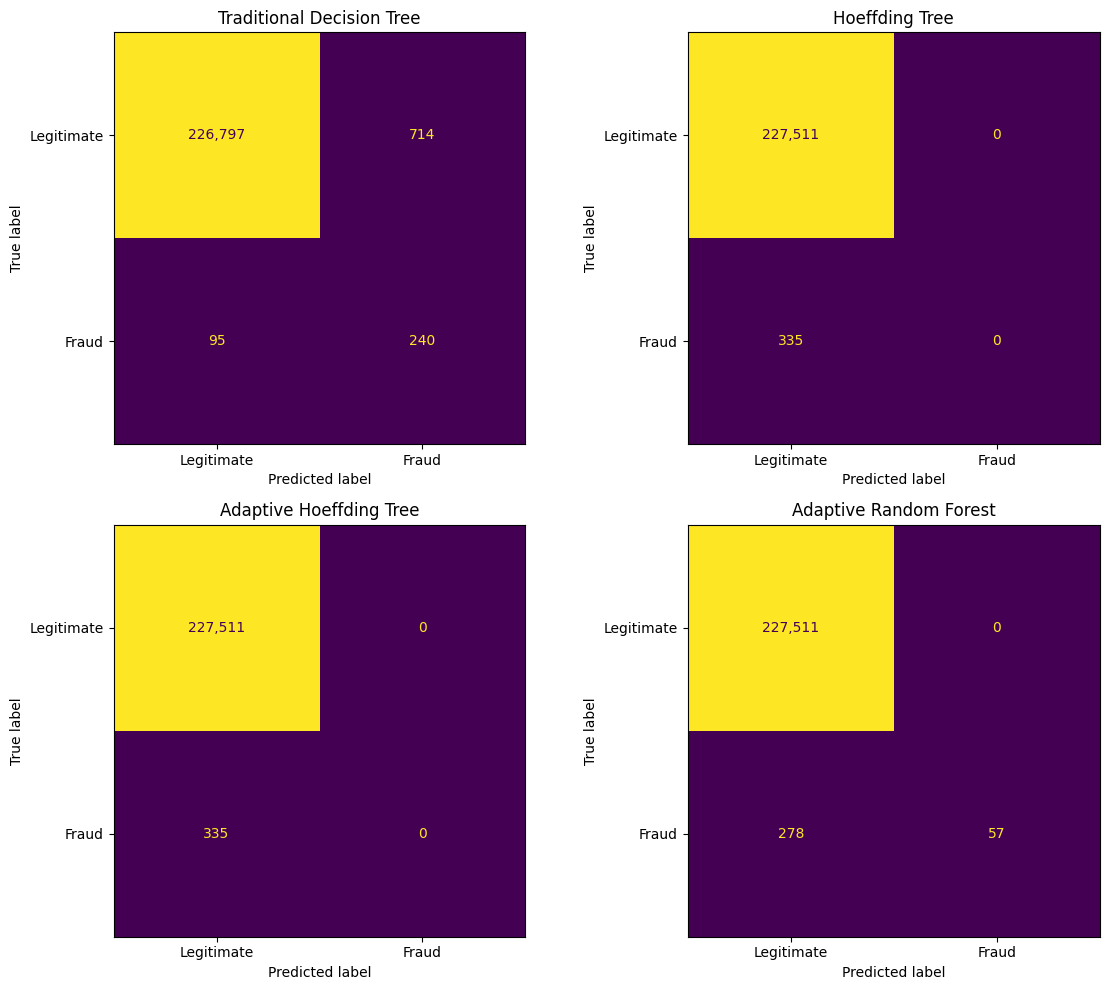

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, predictions) in zip(axes, all_predictions.items()):

    cm = confusion_matrix(
        y_eval,
        predictions,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraud"]
    )

    disp.plot(
        ax=ax,
        values_format=",",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
np.random.seed(42)

N_SYNTHETIC = 12000
DRIFT_POINT = 6000
WARMUP = 1000

X_syn = np.random.randn(N_SYNTHETIC, 2)

y_syn = np.zeros(N_SYNTHETIC, dtype=int)

# Original concept: x1 determines the class
y_syn[:DRIFT_POINT] = (
    X_syn[:DRIFT_POINT, 0] > 0
).astype(int)

# New concept: x2 determines the class
y_syn[DRIFT_POINT:] = (
    X_syn[DRIFT_POINT:, 1] > 0
).astype(int)

# Add 5% label noise
noise = np.random.rand(N_SYNTHETIC) < 0.05
y_syn[noise] = 1 - y_syn[noise]

# Initialize fresh models for this separate experiment
synthetic_models = {
    "Hoeffding Tree": tree.HoeffdingTreeClassifier(
        grace_period=100,
        delta=1e-5
    ),
    "Adaptive Hoeffding Tree": tree.HoeffdingAdaptiveTreeClassifier(
        grace_period=100,
        delta=1e-5
    ),
    "Adaptive Random Forest": forest.ARFClassifier(
        n_models=5,
        seed=42
    )
}

synthetic_batch = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

synthetic_batch.fit(X_syn[:WARMUP], y_syn[:WARMUP])

# Warm up each online model
for i in range(WARMUP):
    x = {"x1": float(X_syn[i, 0]), "x2": float(X_syn[i, 1])}
    for model in synthetic_models.values():
        model.learn_one(x, int(y_syn[i]))

synthetic_predictions = {
    "Traditional Decision Tree": []
}

for name in synthetic_models:
    synthetic_predictions[name] = []

# Prequential evaluation
for i in range(WARMUP, N_SYNTHETIC):

    x = {"x1": float(X_syn[i, 0]), "x2": float(X_syn[i, 1])}
    label = int(y_syn[i])

    # Static baseline: no updates
    batch_pred = synthetic_batch.predict(
        X_syn[i].reshape(1, -1)
    )[0]

    synthetic_predictions["Traditional Decision Tree"].append(
        int(batch_pred)
    )

    for name, model in synthetic_models.items():

        prediction = model.predict_one(x)

        if prediction is None:
            prediction = 0

        synthetic_predictions[name].append(int(prediction))

        # Update only after predicting
        model.learn_one(x, label)

print("Controlled concept-drift experiment completed.")

Controlled concept-drift experiment completed.


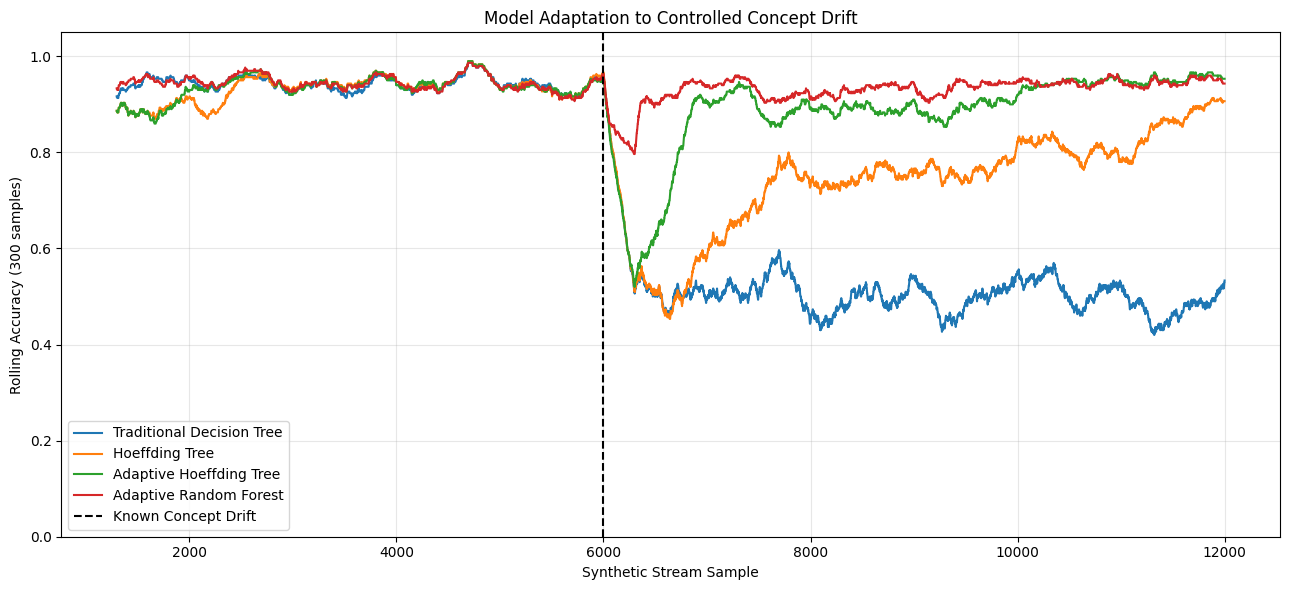

In [ ]:
synthetic_results = []

for name, predictions in synthetic_predictions.items():

    actual = y_syn[WARMUP:]
    correct = (np.asarray(predictions) == actual).astype(float)

    rolling = pd.Series(correct).rolling(
        300, min_periods=300
    ).mean()

    sample_numbers = np.arange(WARMUP, N_SYNTHETIC)

    synthetic_results.append(
        pd.DataFrame({
            "Sample": sample_numbers,
            "Model": name,
            "Rolling Accuracy": rolling.to_numpy()
        })
    )

synthetic_results_df = pd.concat(
    synthetic_results,
    ignore_index=True
)

plt.figure(figsize=(13, 6))

for name, group in synthetic_results_df.groupby("Model", sort=False):
    plt.plot(
        group["Sample"],
        group["Rolling Accuracy"],
        label=name
    )

plt.axvline(
    DRIFT_POINT,
    color="black",
    linestyle="--",
    label="Known Concept Drift"
)

plt.xlabel("Synthetic Stream Sample")
plt.ylabel("Rolling Accuracy (300 samples)")
plt.title("Model Adaptation to Controlled Concept Drift")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Sample,Nodes
55,11200,17
56,11400,17
57,11600,17
58,11800,17
59,12000,17


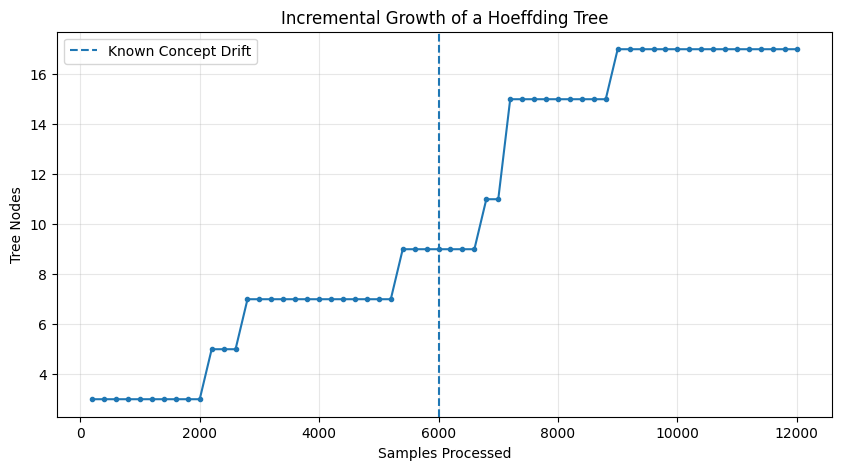

In [ ]:
growth_model = tree.HoeffdingTreeClassifier(
    grace_period=100,
    delta=1e-5
)

growth_records = []

for i in range(N_SYNTHETIC):

    x = {
        "x1": float(X_syn[i, 0]),
        "x2": float(X_syn[i, 1])
    }

    growth_model.learn_one(x, int(y_syn[i]))

    if (i + 1) % 200 == 0:

        nodes = getattr(growth_model, "n_nodes", None)

        if callable(nodes):
            nodes = nodes()

        growth_records.append({
            "Sample": i + 1,
            "Nodes": nodes
        })

growth_df = pd.DataFrame(growth_records)

display(growth_df.tail())

if growth_df["Nodes"].notna().any():
    plt.figure(figsize=(10, 5))

    plt.plot(
        growth_df["Sample"],
        growth_df["Nodes"],
        marker="."
    )

    plt.axvline(
        DRIFT_POINT,
        linestyle="--",
        label="Known Concept Drift"
    )

    plt.xlabel("Samples Processed")
    plt.ylabel("Tree Nodes")
    plt.title("Incremental Growth of a Hoeffding Tree")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("This River version does not expose the node count.")

In [ ]:
synthetic_summary = []

for name, predictions in synthetic_predictions.items():

    predictions = np.asarray(predictions)
    actual = y_syn[WARMUP:]
    samples = np.arange(WARMUP, N_SYNTHETIC)

    before = samples < DRIFT_POINT
    after = samples >= DRIFT_POINT

    synthetic_summary.append({
        "Model": name,
        "Accuracy Before Drift": accuracy_score(
            actual[before], predictions[before]
        ),
        "Accuracy After Drift": accuracy_score(
            actual[after], predictions[after]
        ),
        "Accuracy Change": (
            accuracy_score(actual[after], predictions[after])
            - accuracy_score(actual[before], predictions[before])
        )
    })

synthetic_summary_df = pd.DataFrame(
    synthetic_summary
).set_index("Model")

display(synthetic_summary_df.round(4))

,Accuracy Before Drift,Accuracy After Drift,Accuracy Change
Model,,,
Traditional Decision Tree,0.9428,0.5008,-0.4420
Hoeffding Tree,0.9326,0.7420,-0.1906
Adaptive Hoeffding Tree,0.9352,0.8848,-0.0504
Adaptive Random Forest,0.9452,0.9300,-0.0152
